<a href="https://colab.research.google.com/github/mangeshdhuri11x-art/CE07-Roll_No_Machine-Learning-Lab/blob/main/ML_Experiment_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Student Name :Mangesh Dhuri

Batch :CE1


Roll Number :CE07

### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

from google.colab import files
uploaded = files.upload()

# Load the uploaded CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("\nFirst 5 rows:")
print(df.head())

print("\nDataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())


Saving Mall_Customers.csv to Mall_Customers.csv
Dataset loaded successfully!

First 5 rows:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Dataset Shape: (200, 5)

Column Names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [ ]:

# Select target features
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Display results
print("Selected Features:")
print(X.head())

print("\nFirst 5 Rows After Standardization:")
print(pd.DataFrame(
    X_scaled,
    columns=['Annual Income (k$)', 'Spending Score (1-100)']
).head())

print("\nMean of Scaled Features:")
print(X_scaled.mean(axis=0).round(2))

print("\nStandard Deviation of Scaled Features:")
print(X_scaled.std(axis=0).round(2))


Selected Features:
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40

First 5 Rows After Standardization:
   Annual Income (k$)  Spending Score (1-100)
0           -1.738999               -0.434801
1           -1.738999                1.195704
2           -1.700830               -1.715913
3           -1.700830                1.040418
4           -1.662660               -0.395980

Mean of Scaled Features:
[-0. -0.]

Standard Deviation of Scaled Features:
[1. 1.]


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

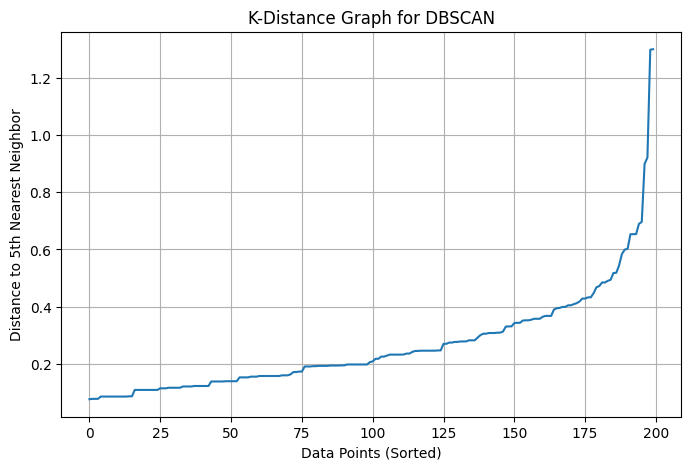

In [ ]:

# Set min_samples
min_samples = 5

# Compute Nearest Neighbors
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Sort k-distances
k_distances = np.sort(distances[:, min_samples - 1])

# Plot k-distance graph
plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.xlabel("Data Points (Sorted)")
plt.ylabel("Distance to 5th Nearest Neighbor")
plt.title("K-Distance Graph for DBSCAN")
plt.grid(True)
plt.show()


# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

In [ ]:

from sklearn.cluster import DBSCAN

# Set DBSCAN parameters
eps_value = 0.3
min_samples = 5

# Create and fit DBSCAN model
dbscan = DBSCAN(eps=eps_value, min_samples=min_samples)
df['Cluster'] = dbscan.fit_predict(X_scaled)

# Display cluster assignments
print("First 10 Cluster Labels:")
print(df[['CustomerID', 'Cluster']].head(10))

# Count points in each cluster
print("\nCluster Counts:")
print(df['Cluster'].value_counts().sort_index())

# Count clusters and noise points
n_clusters = len(set(df['Cluster']) - {-1})
n_noise = (df['Cluster'] == -1).sum()

print("\nNumber of Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)


First 10 Cluster Labels:
   CustomerID  Cluster
0           1        2
1           2        0
2           3        1
3           4        0
4           5        2
5           6        0
6           7        1
7           8       -1
8           9        1
9          10        0

Cluster Counts:
Cluster
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64

Number of Clusters: 7
Number of Noise Points: 35


# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [ ]:

from sklearn.metrics import silhouette_score

# Get cluster labels
labels = df['Cluster']

# 1. Count clusters excluding noise (-1)
n_clusters = len(set(labels) - {-1})
print("Number of Clusters:", n_clusters)

# 2. Count and analyze noise points
n_noise = (labels == -1).sum()
print("Number of Noise Points:", n_noise)
print("Noise Percentage:", round((n_noise / len(df)) * 100, 2), "%")

# 3. Calculate Silhouette Score excluding noise
mask = labels != -1
X_eval = X_scaled[mask]
labels_eval = labels[mask]

if 2 <= len(set(labels_eval)) < len(labels_eval):
    score = silhouette_score(X_eval, labels_eval)
    print("Silhouette Score:", round(score, 4))
else:
    print("Silhouette Score cannot be calculated.")
    print("DBSCAN must produce at least 2 clusters excluding noise.")

# Cluster-wise counts
print("\nCluster-wise Point Counts:")
print(labels.value_counts().sort_index())


Number of Clusters: 7
Number of Noise Points: 35
Noise Percentage: 17.5 %
Silhouette Score: 0.5243

Cluster-wise Point Counts:
Cluster
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

In [ ]:

# Append cluster labels to the original dataset
df['Cluster'] = dbscan.labels_

# Calculate mean statistics for each cluster
print("Cluster Statistics (Mean Values):")
print(
    df[df['Cluster'] != -1]
    .groupby('Cluster')[
        ['Annual Income (k$)', 'Spending Score (1-100)']
    ]
    .mean()
    .round(2)
)

# Count customers in each cluster, including noise
print("\nCluster Counts (including noise):")
print(df['Cluster'].value_counts().sort_index())

# Analyze noise points
noise = df[df['Cluster'] == -1]

print("\nNumber of Noise Points:", len(noise))
print("\nNoise Point Details:")
print(noise[['CustomerID', 'Annual Income (k$)',
             'Spending Score (1-100)']].head(10))

# Display final dataset
print("\nFinal Dataset:")
print(df.head())


Cluster Statistics (Mean Values):
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                     23.17                   74.58
1                     19.60                    6.60
2                     22.43                   34.43
3                     55.23                   48.58
4                     79.53                   83.13
5                     75.93                   10.07
6                     88.78                   17.00

Cluster Counts (including noise):
Cluster
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64

Number of Noise Points: 35

Noise Point Details:
    CustomerID  Annual Income (k$)  Spending Score (1-100)
7            8                  18                      94
10          11                  19                      14
11          12                  19                      99
12          13                  20                      15
19          

# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.